In [1]:
!pip -q install pandas numpy scikit-learn matplotlib

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("UEBA environment is ready!")

UEBA environment is ready!


Synthetic employee activity logs

In [6]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 2000

users = [f"employee_{i:03d}" for i in range(1, 51)]

df = pd.DataFrame({
    "user_id": rng.choice(users, n),
    "hour": rng.integers(0, 24, n),
    "bytes_transferred": rng.lognormal(mean=12, sigma=1.0, size=n).astype(int),
    "files_accessed": rng.poisson(5, n),
    "sensitive_access": rng.binomial(1, 0.08, n)
})

# Synthetic ground-truth labels for demonstration
df["label"] = 0

# Simulate a suspicious subset
idx = rng.choice(df.index, size=100, replace=False)

df.loc[idx, "label"] = 1
df.loc[idx, "hour"] = rng.choice([0, 1, 2, 3, 4], len(idx))
df.loc[idx, "bytes_transferred"] = rng.integers(15_000_000, 100_000_000, len(idx))
df.loc[idx, "files_accessed"] = rng.integers(20, 100, len(idx))
df.loc[idx, "sensitive_access"] = 1

df["timestamp"] = (
    pd.Timestamp("2026-01-01")
    + pd.to_timedelta(rng.integers(0, 30 * 24, n), unit="h")
)

df = df.sort_values("timestamp").reset_index(drop=True)

df.to_csv("employee_activity.csv", index=False)

print(df.head())
print("Rows:", len(df))
print("Synthetic suspicious events:", int(df["label"].sum()))

        user_id  hour  bytes_transferred  files_accessed  sensitive_access  \
0  employee_018    23             265134               6                 1   
1  employee_031     6             165776               8                 0   
2  employee_021    22             433150               5                 0   
3  employee_040     9             126100               7                 0   
4  employee_049    10             169453               2                 0   

   label           timestamp  
0      0 2026-01-01 00:00:00  
1      0 2026-01-01 00:00:00  
2      0 2026-01-01 00:00:00  
3      0 2026-01-01 00:00:00  
4      0 2026-01-01 02:00:00  
Rows: 2000
Synthetic suspicious events: 100


Train the anomaly-detection model

In [8]:
features = [
    "hour",
    "bytes_transferred",
    "files_accessed",
    "sensitive_access"
]

X = df[features].copy()

# Reduce the impact of very large transfer values
X["bytes_transferred"] = np.log1p(X["bytes_transferred"])

model = IsolationForest(
    n_estimators=150,
    contamination=0.05,
    random_state=42
)

model.fit(X)

# -1 = anomaly; 1 = normal
df["ml_prediction"] = model.predict(X)

df["ml_anomaly"] = (
    df["ml_prediction"] == -1
).astype(int)

print(df["ml_anomaly"].value_counts())

ml_anomaly
0    1900
1     100
Name: count, dtype: int64


Risk-scoring system

In [10]:
df["risk_score"] = 0

df["risk_score"] += (
    df["ml_anomaly"] * 30
)

df["risk_score"] += (
    ((df["hour"] < 6) | (df["hour"] >= 22)).astype(int) * 15
)

df["risk_score"] += (
    (df["bytes_transferred"] >= 10_000_000).astype(int) * 25
)

df["risk_score"] += (
    (df["files_accessed"] >= 20).astype(int) * 20
)

df["risk_score"] += (
    (df["sensitive_access"] == 1).astype(int) * 10
)

df["severity"] = pd.cut(
    df["risk_score"],
    bins=[-1, 24, 49, 74, 200],
    labels=["LOW", "MEDIUM", "HIGH", "CRITICAL"]
)

df["alert"] = (
    (df["risk_score"] >= 50)
    | (df["ml_anomaly"] == 1)
)

alerts = df[df["alert"]].copy()

alerts.to_csv("ueba_alerts.csv", index=False)

print("Total events:", len(df))
print("Alerts generated:", len(alerts))
print(
    alerts[
        ["user_id", "hour", "risk_score", "severity"]
    ].head(10)
)

Total events: 2000
Alerts generated: 107
          user_id  hour  risk_score  severity
63   employee_023     2         100  CRITICAL
102  employee_028     1         100  CRITICAL
127  employee_035     4         100  CRITICAL
144  employee_009     4         100  CRITICAL
145  employee_003     0         100  CRITICAL
186  employee_024    23          55      HIGH
192  employee_017     3         100  CRITICAL
195  employee_024     2         100  CRITICAL
209  employee_047     4         100  CRITICAL
218  employee_043     1         100  CRITICAL


Evaluate the model

In [12]:
print(confusion_matrix(
    df["label"],
    df["ml_anomaly"]
))

print(classification_report(
    df["label"],
    df["ml_anomaly"],
    zero_division=0
))

[[1893    7]
 [   7   93]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1900
           1       0.93      0.93      0.93       100

    accuracy                           0.99      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.99      0.99      0.99      2000



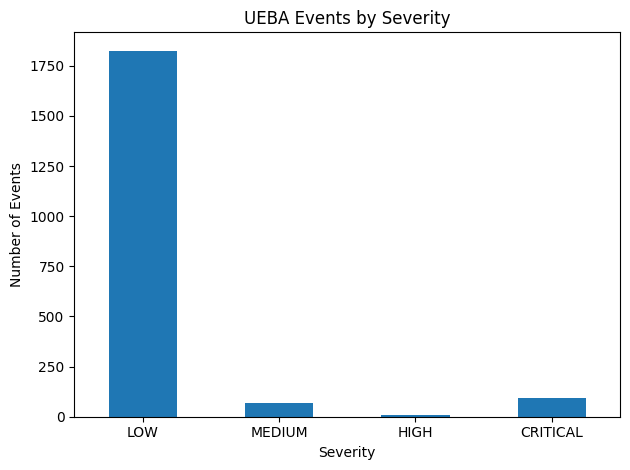

In [15]:
df["severity"].value_counts().reindex(
    ["LOW", "MEDIUM", "HIGH", "CRITICAL"],
    fill_value=0
).plot(kind="bar")

plt.title("UEBA Events by Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

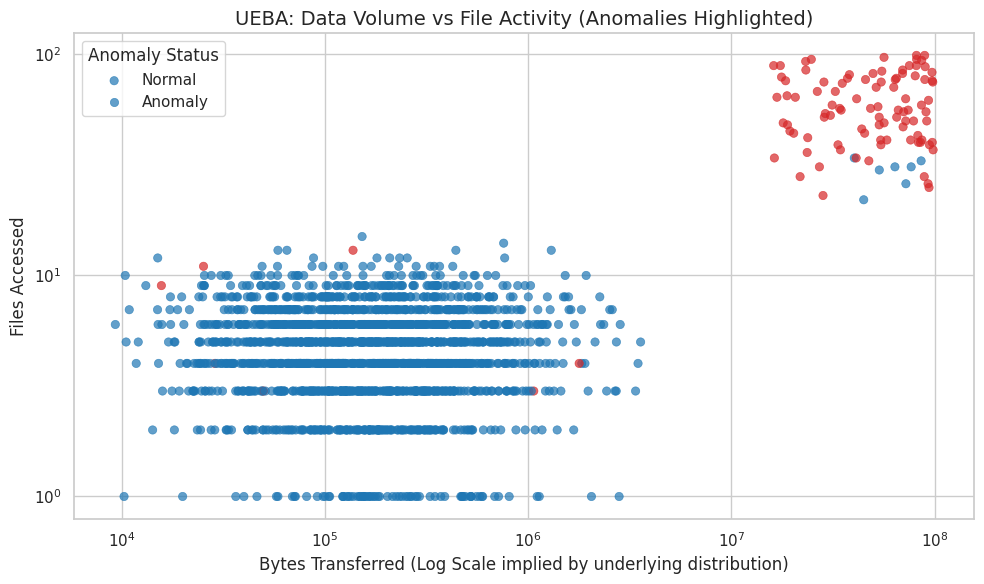

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Scatter plot mapping Bytes Transferred vs Files Accessed, highlighting ML anomalies
sns.scatterplot(
    data=df,
    x="bytes_transferred",
    y="files_accessed",
    hue="ml_anomaly",
    palette={0: "#1f77b4", 1: "#d62728"},
    alpha=0.7,
    edgecolor=None
)

plt.title("UEBA: Data Volume vs File Activity (Anomalies Highlighted)", fontsize=14)
plt.xlabel("Bytes Transferred (Log Scale implied by underlying distribution)", fontsize=12)
plt.ylabel("Files Accessed", fontsize=12)
plt.yscale("log")  # Using log scale due to severe skewness
plt.xscale("log")
plt.legend(title="Anomaly Status", labels=["Normal", "Anomaly"])
plt.tight_layout()
plt.show()

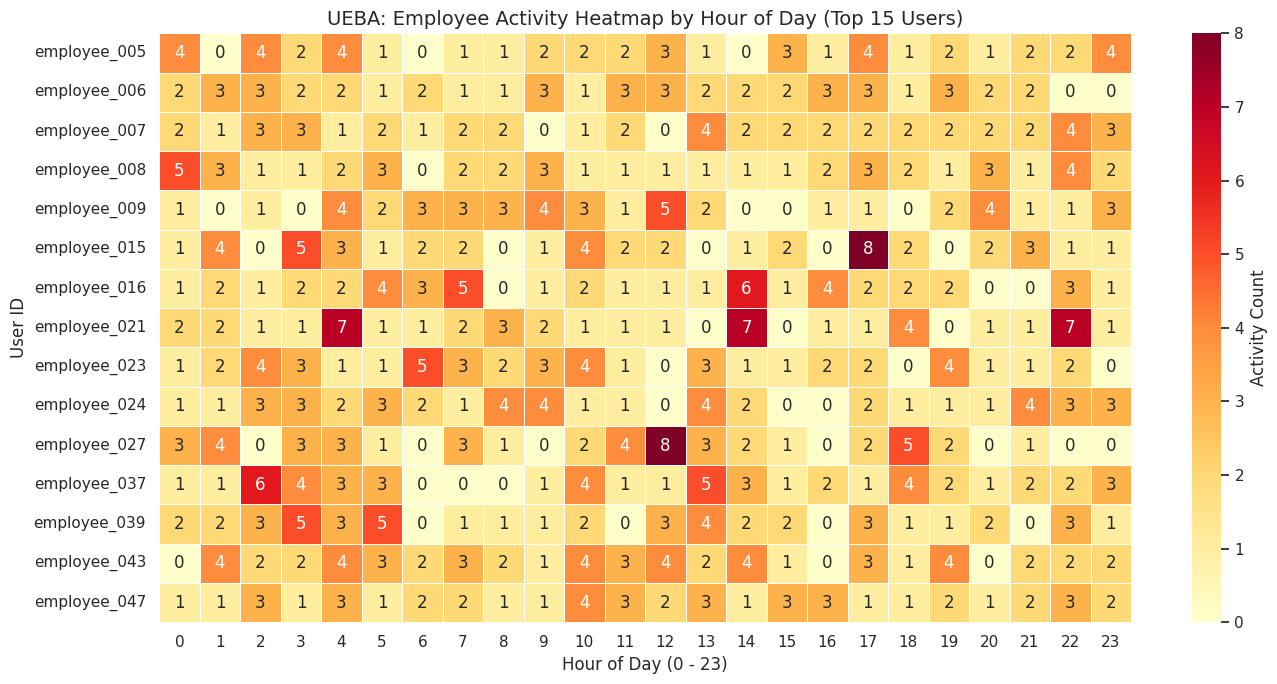

In [17]:
# Get the top 15 most active users to keep the heatmap readable
top_users = df['user_id'].value_counts().nlargest(15).index
filtered_df = df[df['user_id'].isin(top_users)]

# Create a pivot table: Rows = Users, Columns = Hours, Values = Activity Counts
pivot_df = pd.crosstab(filtered_df['user_id'], filtered_df['hour'])

plt.figure(figsize=(14, 7))
sns.heatmap(
    pivot_df,
    cmap="YlOrRd",
    linewidths=0.5,
    annot=True,
    fmt="d",
    cbar_kws={'label': 'Activity Count'}
)

plt.title("UEBA: Employee Activity Heatmap by Hour of Day (Top 15 Users)", fontsize=14)
plt.xlabel("Hour of Day (0 - 23)", fontsize=12)
plt.ylabel("User ID", fontsize=12)
plt.tight_layout()
plt.show()

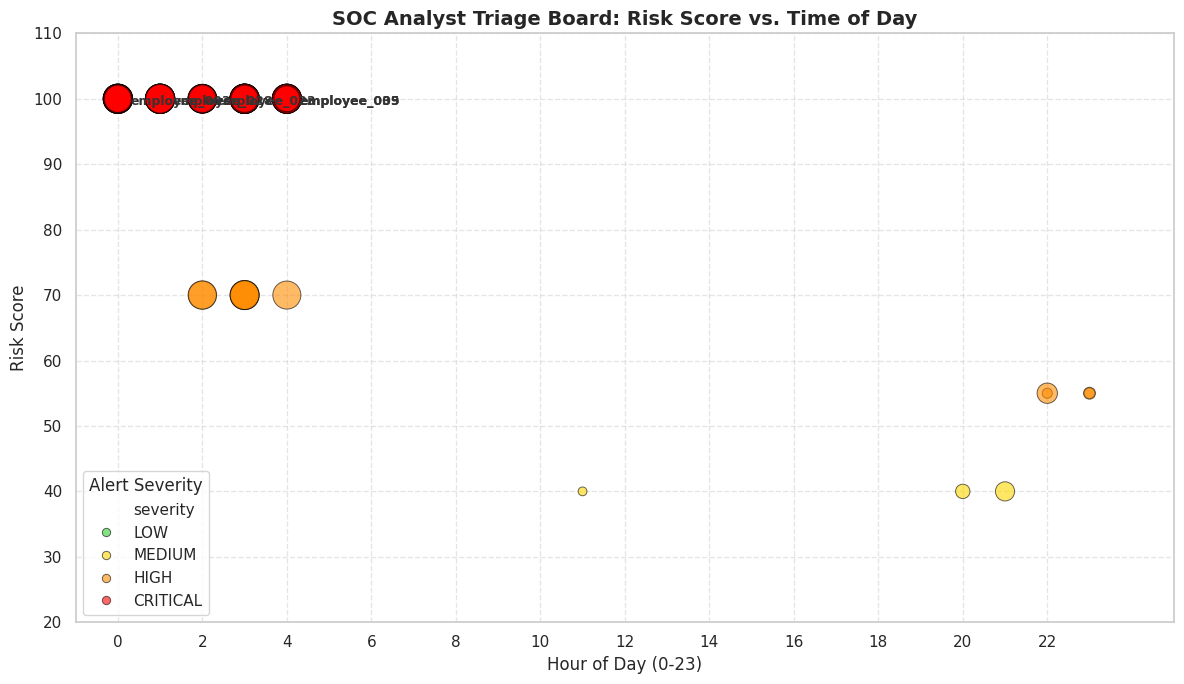

In [18]:
plt.figure(figsize=(12, 7))

# Map colors specifically for risk severity tiers
severity_colors = {
    "LOW": "#32cd32",       # Lime Green
    "MEDIUM": "#ffd700",    # Gold
    "HIGH": "#ff8c00",      # Dark Orange
    "CRITICAL": "#ff0000"    # Red
}

# Calculate a display size variable for bubbles (scaling bytes_transferred for visual representation)
alerts_display = alerts.copy()
alerts_display["bubble_size"] = np.log1p(alerts_display["bytes_transferred"]) ** 2.5

sns.scatterplot(
    data=alerts_display,
    x="hour",
    y="risk_score",
    hue="severity",
    size="bubble_size",
    sizes=(40, 450),
    palette=severity_colors,
    hue_order=["LOW", "MEDIUM", "HIGH", "CRITICAL"],
    alpha=0.6,
    edgecolor="black",
    linewidth=0.7
)

# Annotate the most critical alerts to guide the analyst's eye
critical_alerts = alerts_display[alerts_display["severity"] == "CRITICAL"].head(5)
for _, row in critical_alerts.iterrows():
    plt.text(
        row["hour"] + 0.3,
        row["risk_score"] - 1,
        row["user_id"],
        fontsize=9,
        weight="bold",
        color="#333333"
    )

plt.title("SOC Analyst Triage Board: Risk Score vs. Time of Day", fontsize=14, weight="bold")
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Risk Score", fontsize=12)
plt.xlim(-1, 25)
plt.ylim(20, 110)
plt.xticks(range(0, 24, 2))

# Clean up the legend
handles, labels = plt.gca().get_legend_handles_labels()
# Display only the first 5 legend items (Severities) and skip the size scale legend entries
plt.legend(handles[0:5], labels[0:5], title="Alert Severity", loc="lower left", frameon=True)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [20]:
df.to_csv("employee_activity.csv", index=False)
alerts.to_csv("ueba_alerts.csv", index=False)

alerts.to_json(
    "ueba_alerts.jsonl",
    orient="records",
    lines=True
)

print("CSV and JSONL exports created.")

CSV and JSONL exports created.


In [22]:
# Equivalent Python pandas aggregation of your Splunk query
# Grouping by user_id and severity, counting alerts, and sorting in descending order

soc_rankings = (
    alerts.groupby(["user_id", "severity"], observed=False)
    .size()
    .reset_index(name="count")
    .sort_values(by="count", ascending=False)
)

print(soc_rankings.head(10))

          user_id  severity  count
163  employee_047  CRITICAL      6
143  employee_041  CRITICAL      5
15   employee_004  CRITICAL      4
47   employee_013  CRITICAL      4
103  employee_029  CRITICAL      4
95   employee_027  CRITICAL      4
155  employee_045  CRITICAL      4
3    employee_001  CRITICAL      3
55   employee_015  CRITICAL      3
99   employee_028  CRITICAL      3


investigate large transfer

In [24]:
# Python Pandas equivalent of the Splunk query
# Filtering for events where bytes_transferred >= 10,000,000 (10MB)

large_transfers = df[df["bytes_transferred"] >= 10_000_000][
    ["timestamp", "user_id", "bytes_transferred", "files_accessed", "severity"]
].sort_values(by="bytes_transferred", ascending=False)

print(large_transfers.head(10))

               timestamp       user_id  bytes_transferred  files_accessed  \
460  2026-01-07 15:00:00  employee_045           98158020              37   
192  2026-01-03 11:00:00  employee_017           97775467              75   
900  2026-01-14 03:00:00  employee_046           97234410              40   
218  2026-01-03 20:00:00  employee_043           97106615              76   
735  2026-01-11 11:00:00  employee_004           96931381              83   
454  2026-01-07 14:00:00  employee_004           94167181              39   
536  2026-01-08 18:00:00  employee_028           93700421              25   
1936 2026-01-30 00:00:00  employee_040           93196214              62   
1245 2026-01-19 07:00:00  employee_041           92713750              26   
810  2026-01-12 18:00:00  employee_001           91326245              50   

      severity  
460   CRITICAL  
192   CRITICAL  
900   CRITICAL  
218   CRITICAL  
735   CRITICAL  
454   CRITICAL  
536   CRITICAL  
1936  CRITICAL  

Find repeated alert users

In [26]:
# Python Pandas equivalent of the Splunk query
# Aggregating alert count and maximum risk score grouped by user_id

repeated_alerts = (
    alerts.groupby("user_id")
    .agg(alert_count=("alert", "count"), max_risk=("risk_score", "max"))
    .reset_index()
    .sort_values(by="alert_count", ascending=False)
)

print(repeated_alerts.head(10))

         user_id  alert_count  max_risk
40  employee_047            6       100
25  employee_029            6       100
23  employee_027            5       100
35  employee_041            5       100
38  employee_045            5       100
24  employee_028            4       100
20  employee_024            4       100
11  employee_013            4       100
4   employee_005            4       100
3   employee_004            4       100


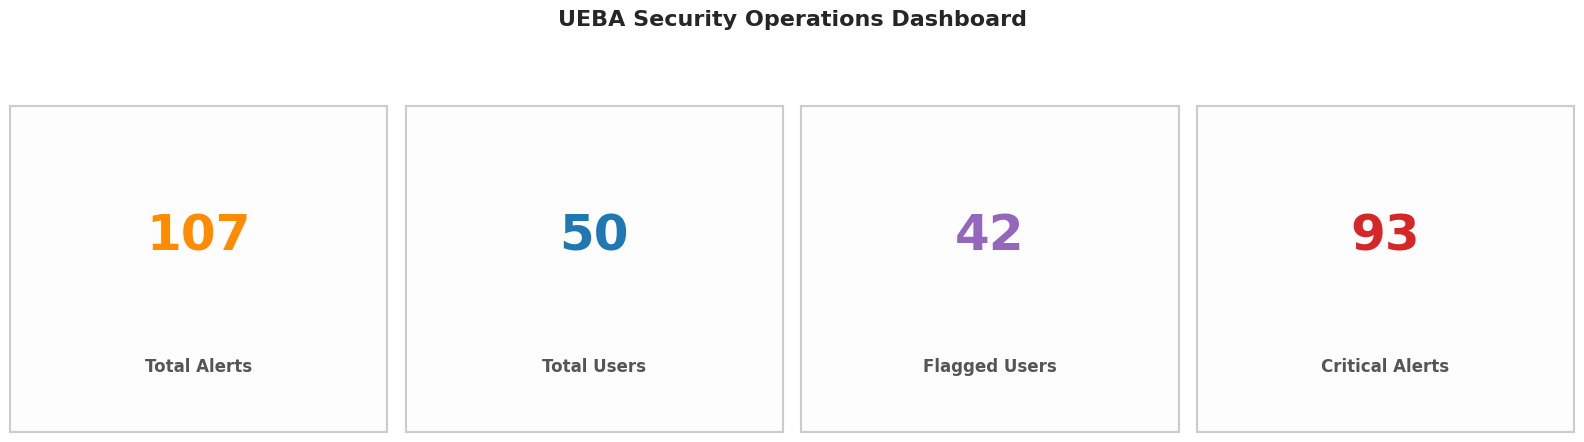

In [27]:
import matplotlib.pyplot as plt

# Calculate summary metrics
total_alerts = len(alerts)
total_users = df['user_id'].nunique()
flagged_users = alerts['user_id'].nunique()
critical_alerts = len(alerts[alerts['severity'] == 'CRITICAL'])

# Create a visual KPI dashboard
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('UEBA Security Operations Dashboard', fontsize=16, weight='bold', y=1.1)

metrics = [
    ("Total Alerts", total_alerts, "#ff8c00"),
    ("Total Users", total_users, "#1f77b4"),
    ("Flagged Users", flagged_users, "#9467bd"),
    ("Critical Alerts", critical_alerts, "#d62728")
]

for i, (title, val, color) in enumerate(metrics):
    ax = axs[i]
    ax.set_facecolor('#fdfdfd')
    ax.text(0.5, 0.6, str(val), fontsize=36, weight='bold', color=color, ha='center', va='center')
    ax.text(0.5, 0.2, title, fontsize=12, weight='bold', color='#555555', ha='center', va='center')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color('#cccccc')
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

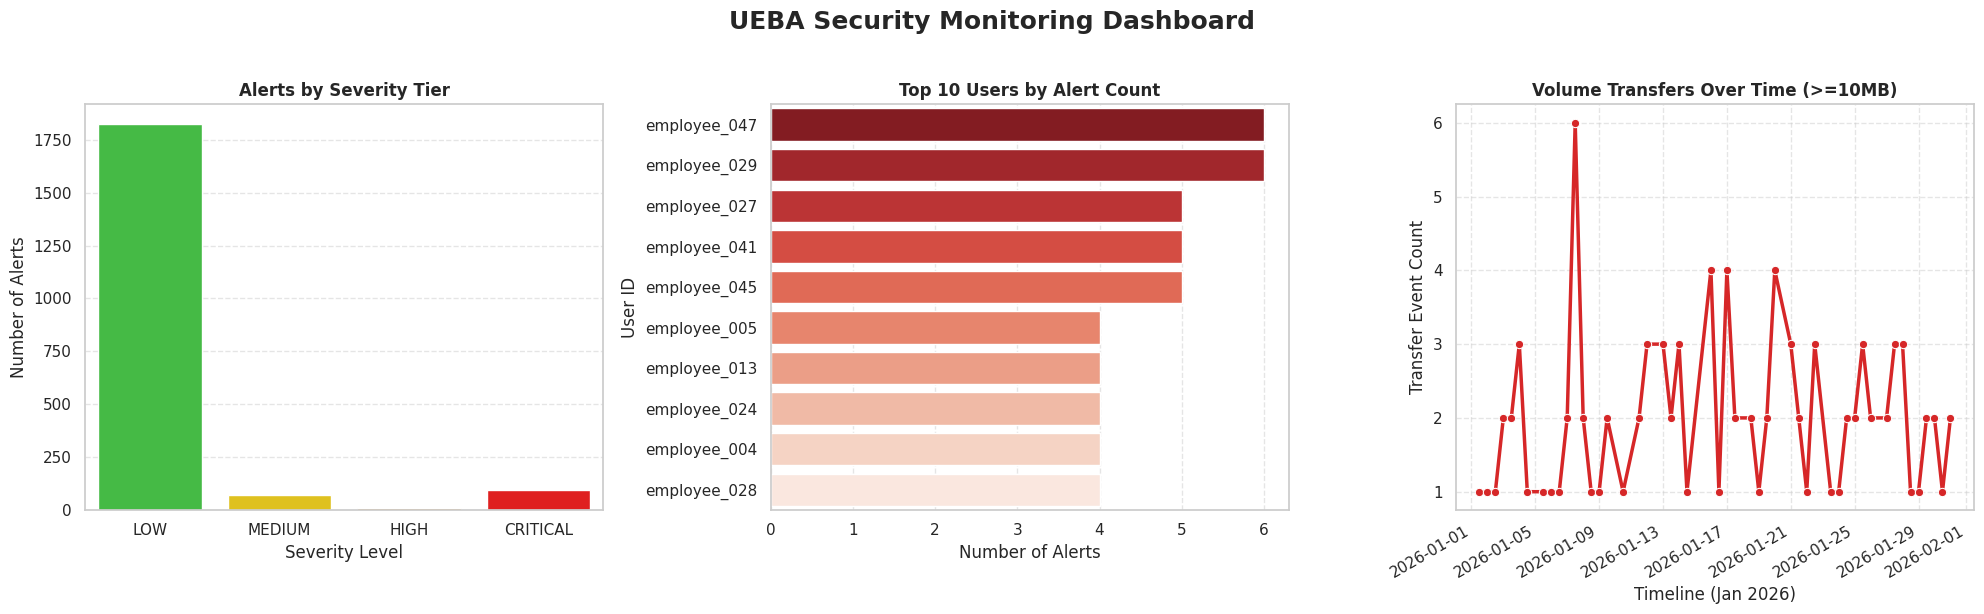

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configure subplot canvas
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("UEBA Security Monitoring Dashboard", fontsize=18, weight='bold', y=1.02)

# 1. Alerts by Severity
severity_counts = df['severity'].value_counts().reindex(["LOW", "MEDIUM", "HIGH", "CRITICAL"], fill_value=0)
severity_colors_list = ["#32cd32", "#ffd700", "#ff8c00", "#ff0000"]
sns.barplot(ax=axs[0], x=severity_counts.index, y=severity_counts.values, palette=severity_colors_list, hue=severity_counts.index, legend=False)
axs[0].set_title("Alerts by Severity Tier", fontsize=12, weight='bold')
axs[0].set_xlabel("Severity Level")
axs[0].set_ylabel("Number of Alerts")
axs[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Top Users by Alert Count
top_flagged = alerts['user_id'].value_counts().head(10).reset_index(name='count')
sns.barplot(ax=axs[1], x='count', y='user_id', data=top_flagged, palette="Reds_r", hue='user_id', legend=False)
axs[1].set_title("Top 10 Users by Alert Count", fontsize=12, weight='bold')
axs[1].set_xlabel("Number of Alerts")
axs[1].set_ylabel("User ID")
axs[1].grid(axis='x', linestyle='--', alpha=0.5)

# 3. Large Transfers Over Time
# Resampling to 12-hour intervals for a smooth timeline presentation
large_transfers_timeline = df[df['bytes_transferred'] >= 10_000_000].copy()
large_transfers_timeline['time_bucket'] = large_transfers_timeline['timestamp'].dt.round('12h')
timeline_data = large_transfers_timeline.groupby('time_bucket').size().reset_index(name='event_count')

sns.lineplot(ax=axs[2], x='time_bucket', y='event_count', data=timeline_data, marker='o', color='#d62728', linewidth=2.5)
axs[2].set_title("Volume Transfers Over Time (>=10MB)", fontsize=12, weight='bold')
axs[2].set_xlabel("Timeline (Jan 2026)")
axs[2].set_ylabel("Transfer Event Count")
plt.setp(axs[2].get_xticklabels(), rotation=30, ha='right')
axs[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()